#Práctica 3: K-means

#Implementa una comparación entre los resultados obtenidos y los resultados reales.



--- TABLA DE CONTINGENCIA ---
Cluster K-Means   0   1   2
Especie Real               
0                 0  50   0
1                48   0   2
2                14   0  36

--- MÉTRICAS DE EVALUACIÓN ---
Adjusted Rand Index (ARI): 0.7302
Normalized Mutual Information (NMI): 0.7582


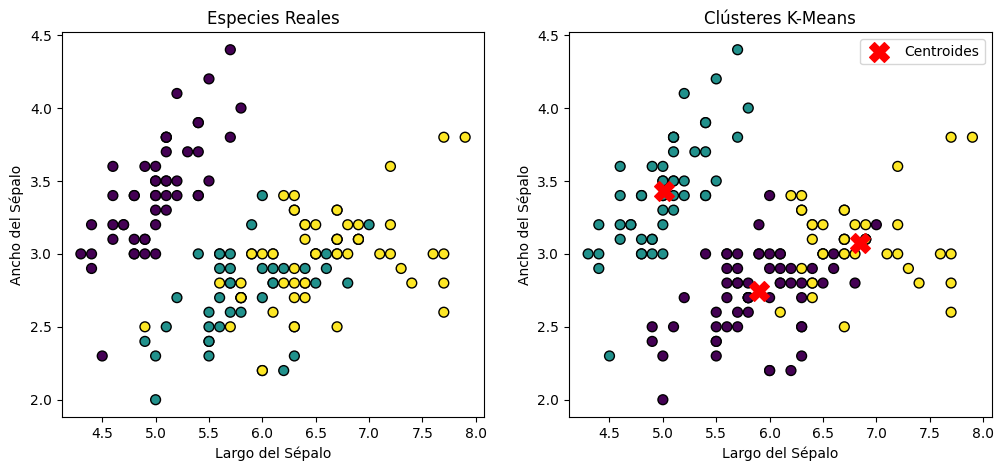

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
#Cargamos los datos Iris
iris = datasets.load_iris()
X = iris.data
y_real = iris.target
#Se crea el modelo de aprendizaje, indicando que se buscan 3 grupos
n_clusters = 3
modelo = KMeans(n_clusters=n_clusters, random_state=0, n_init=10)
#El modelo adquiere los datos Iris y busca las 3 agrupaciones
modelo.fit(X)
#Se obtienen los grupos encontrados
y_pred = modelo.labels_
#Se comparan las especies reales con los grupos encontrados y se muestra en la ejecución del código
tabla_contingencia = pd.crosstab(
    pd.Series(y_real, name='Especie Real'),
    pd.Series(y_pred, name='Cluster K-Means')
)

print("--- TABLA DE CONTINGENCIA ---")
print(tabla_contingencia)
#Se usan dos métricas para evaluar la calidad de los agrupamientos
ari = adjusted_rand_score(y_real, y_pred)
nmi = normalized_mutual_info_score(y_real, y_pred)

print("\n--- MÉTRICAS DE EVALUACIÓN ---")
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")
#Se crean gráficos para tener una comparación visual en el código ejecutado
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X[:, 0], X[:, 1], c=y_real, cmap='viridis', edgecolor='k', s=50)
axes[0].set_title('Especies Reales')
axes[0].set_xlabel('Largo del Sépalo')
axes[0].set_ylabel('Ancho del Sépalo')

axes[1].scatter(X[:, 0], X[:, 1], c=y_pred, cmap='viridis', edgecolor='k', s=50)
centroides = modelo.cluster_centers_
axes[1].scatter(centroides[:, 0], centroides[:, 1], c='red', marker='X', s=200, label='Centroides')
axes[1].set_title('Clústeres K-Means')
axes[1].set_xlabel('Largo del Sépalo')
axes[1].set_ylabel('Ancho del Sépalo')
axes[1].legend()